# Malintha K K I (IT25102346)
# Feature Engineering using HOG, GLCM and PCA



## Part 1 — Install required libraries

In [1]:
!pip -q install kagglehub scikit-image opencv-python-headless

## Part 2 — Import libraries and download the dataset

In [2]:
from pathlib import Path
import os
import hashlib
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import cv2
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from skimage.feature import hog, graycomatrix, graycoprops

SEED = 42
np.random.seed(SEED)

# Download latest version from Kaggle
path = kagglehub.dataset_download(
    "sartajbhuvaji/brain-tumor-classification-mri"
)

print("Path to dataset files:", path)

DATASET_ROOT = Path(path)
TRAIN_DIR = DATASET_ROOT / "Training"
TEST_DIR = DATASET_ROOT / "Testing"

assert TRAIN_DIR.exists(), f"Training folder not found: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Testing folder not found: {TEST_DIR}"

print("Training folder:", TRAIN_DIR)
print("Testing folder :", TEST_DIR)

Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Path to dataset files: /kaggle/input/brain-tumor-classification-mri
Training folder: /kaggle/input/brain-tumor-classification-mri/Training
Testing folder : /kaggle/input/brain-tumor-classification-mri/Testing


## Part 3 — Build Training and Testing manifests

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def make_manifest(root, split_name):
    rows = []

    for class_dir in sorted([p for p in root.iterdir() if p.is_dir()]):
        for p in sorted(class_dir.rglob("*")):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                rows.append({
                    "split": split_name,
                    "class_name": class_dir.name,
                    "path": str(p)
                })

    return pd.DataFrame(rows)

train_raw = make_manifest(TRAIN_DIR, "Training")
test_raw = make_manifest(TEST_DIR, "Testing")

print("Raw Training images:", len(train_raw))
print("Raw Testing images :", len(test_raw))

display(
    pd.concat({
        "Training": train_raw["class_name"].value_counts().sort_index(),
        "Testing": test_raw["class_name"].value_counts().sort_index()
    }, axis=1).fillna(0).astype(int)
)

Raw Training images: 2870
Raw Testing images : 394


,Training,Testing
class_name,,
glioma_tumor,826,100
meningioma_tumor,822,115
no_tumor,395,105
pituitary_tumor,827,74


## Part 4 — Shared cleaning required before feature engineering

In [4]:
def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def image_is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()

        return True

    except Exception:
        return False


def audit_manifest(df, label):
    out = df.copy()

    out["valid"] = out["path"].map(image_is_valid)
    out["sha256"] = None

    valid_indices = out.index[out["valid"]].tolist()

    for n, idx in enumerate(valid_indices, start=1):
        out.at[idx, "sha256"] = sha256_file(
            out.at[idx, "path"]
        )

        if n % 500 == 0:
            print(
                f"{label}: hashed {n}/{len(valid_indices)}"
            )

    return out


train_audit = audit_manifest(
    train_raw,
    "Training"
)

test_audit = audit_manifest(
    test_raw,
    "Testing"
)

train_valid = train_audit[
    train_audit["valid"]
].copy()

test_valid = test_audit[
    test_audit["valid"]
].copy()

# Remove exact duplicate copies inside Training.
train_valid["duplicate_in_training"] = train_valid.duplicated(
    "sha256",
    keep="first"
)

train_unique = train_valid[
    ~train_valid["duplicate_in_training"]
].copy()

# Preserve official Testing and remove matching copies from Training.
test_hashes = set(
    test_valid["sha256"].dropna()
)

train_unique["overlaps_testing"] = train_unique["sha256"].isin(
    test_hashes
)

train_clean = train_unique[
    ~train_unique["overlaps_testing"]
].copy().reset_index(drop=True)

test_clean = test_valid.copy().reset_index(drop=True)

print("Clean Training images:", len(train_clean))
print("Official Testing images:", len(test_clean))

Training: hashed 500/2870
Training: hashed 1000/2870
Training: hashed 1500/2870
Training: hashed 2000/2870
Training: hashed 2500/2870
Clean Training images: 2713
Official Testing images: 394


## Part 5 — Split cleaned Training into 80% Training and 20% Validation

In [5]:
train_80, validation_20 = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=SEED,
    stratify=train_clean["class_name"]
)

train_80 = train_80.reset_index(drop=True)
validation_20 = validation_20.reset_index(drop=True)
official_test = test_clean.reset_index(drop=True)

print("Actual Training :", len(train_80))
print("Validation      :", len(validation_20))
print("Official Testing:", len(official_test))

split_counts = pd.concat({
    "Train_80": train_80["class_name"].value_counts().sort_index(),
    "Validation_20": validation_20["class_name"].value_counts().sort_index(),
    "Official_Test": official_test["class_name"].value_counts().sort_index()
}, axis=1).fillna(0).astype(int)

display(split_counts)

Actual Training : 2170
Validation      : 543
Official Testing: 394


,Train_80,Validation_20,Official_Test
class_name,,,
glioma_tumor,654,164,100
meningioma_tumor,651,163,115
no_tumor,217,54,105
pituitary_tumor,648,162,74


## Part 6 — Shared resize, padding and CLAHE preprocessing

In [6]:
TARGET_SIZE = (224, 224)
PADDING_VALUE = (0, 0, 0)

CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)


def resize_with_padding(
    image,
    target_size=TARGET_SIZE,
    fill=PADDING_VALUE
):
    image = image.convert("RGB")

    target_w, target_h = target_size
    original_w, original_h = image.size

    scale = min(
        target_w / original_w,
        target_h / original_h
    )

    new_w = max(
        1,
        int(round(original_w * scale))
    )

    new_h = max(
        1,
        int(round(original_h * scale))
    )

    resized = image.resize(
        (new_w, new_h),
        Image.Resampling.LANCZOS
    )

    pad_left = (target_w - new_w) // 2
    pad_top = (target_h - new_h) // 2

    pad_right = target_w - new_w - pad_left
    pad_bottom = target_h - new_h - pad_top

    padded = ImageOps.expand(
        resized,
        border=(
            pad_left,
            pad_top,
            pad_right,
            pad_bottom
        ),
        fill=fill
    )

    return padded


def apply_clahe_rgb(pil_image):
    rgb = np.asarray(
        pil_image.convert("RGB"),
        dtype=np.uint8
    )

    lab = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(
        lab
    )

    clahe = cv2.createCLAHE(
        clipLimit=CLAHE_CLIP,
        tileGridSize=CLAHE_GRID
    )

    enhanced_l = clahe.apply(
        l_channel
    )

    enhanced_lab = cv2.merge(
        [
            enhanced_l,
            a_channel,
            b_channel
        ]
    )

    enhanced_rgb = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(
        enhanced_rgb
    )

## Part 7 — Create processed image files for Member 6

In [7]:
WORK = Path("/content/member6_feature_engineering")
PROCESSED_ROOT = WORK / "processed_images"
OUTPUT_DIR = WORK / "outputs"

PROCESSED_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def preprocess_and_save(df, split_name):
    rows = []

    for n, row in enumerate(
        df.itertuples(index=False),
        start=1
    ):
        src = Path(row.path)

        with Image.open(src) as im:
            resized = resize_with_padding(
                im
            )

        enhanced = apply_clahe_rgb(
            resized
        )

        dst_dir = (
            PROCESSED_ROOT
            / split_name
            / row.class_name
        )

        dst_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        dst = dst_dir / f"{src.stem}.png"

        enhanced.save(
            dst,
            format="PNG"
        )

        rows.append({
            "split": split_name,
            "class_name": row.class_name,
            "source_path": str(src),
            "processed_path": str(dst)
        })

        if n % 500 == 0:
            print(
                f"{split_name}: processed {n}/{len(df)}"
            )

    return pd.DataFrame(
        rows
    )


train_pre = preprocess_and_save(
    train_80,
    "train"
)

val_pre = preprocess_and_save(
    validation_20,
    "validation"
)

test_pre = preprocess_and_save(
    official_test,
    "test"
)

print("Processed Training :", len(train_pre))
print("Processed Validation:", len(val_pre))
print("Processed Test      :", len(test_pre))

train: processed 500/2170
train: processed 1000/2170
train: processed 1500/2170
train: processed 2000/2170
validation: processed 500/543
Processed Training : 2170
Processed Validation: 543
Processed Test      : 394


#  HOG + GLCM + PCA



## Part 8 — Define HOG + GLCM feature extraction

In [8]:
FEATURE_SIZE = (64, 64)


def feature_vector(path):


    # 1. Load processed MRI, grayscale and resize

    with Image.open(path) as im:

        gray_img = (
            im.convert("L")
            .resize(
                FEATURE_SIZE,
                Image.Resampling.LANCZOS
            )
        )


        # Create a writable C-contiguous copy instead.
        gray = np.array(
            gray_img,
            dtype=np.uint8,
            copy=True,
            order="C"
        )

    # Extra safety for current Colab/scikit-image versions.
    gray = np.ascontiguousarray(
        gray
    ).copy()

    gray.setflags(
        write=True
    )


    # 2. HOG features

    h = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    ).astype(
        np.float32
    )


    # 3. GLCM matrix

    g = graycomatrix(
        gray,
        distances=[1],
        angles=[
            0,
            np.pi / 4,
            np.pi / 2,
            3 * np.pi / 4
        ],
        levels=256,
        symmetric=True,
        normed=True
    )

    # 4. GLCM texture properties

    t = np.array(
        [
            graycoprops(
                g,
                "contrast"
            ).mean(),

            graycoprops(
                g,
                "dissimilarity"
            ).mean(),

            graycoprops(
                g,
                "homogeneity"
            ).mean(),

            graycoprops(
                g,
                "energy"
            ).mean(),

            graycoprops(
                g,
                "correlation"
            ).mean()
        ],
        dtype=np.float32
    )

    # 5. Combine HOG + GLCM

    return np.concatenate(
        [h, t]
    )


# Test one MRI first
sample_path = train_pre.iloc[0][
    "processed_path"
]

sample_features = feature_vector(
    sample_path
)

print(
    "Sample image:",
    sample_path
)

print(
    "Raw HOG + GLCM feature count:",
    len(sample_features)
)

print(
    "First 10 feature values:",
    sample_features[:10]
)

print(
    "SUCCESS: HOG + GLCM feature extraction works."
)

Sample image: /content/member6_feature_engineering/processed_images/train/glioma_tumor/gg (404).png
Raw HOG + GLCM feature count: 1769
First 10 feature values: [0.27626586 0.         0.         0.21187168 0.12263761 0.2178413
 0.27626586 0.27626586 0.27626586 0.12263761]
SUCCESS: HOG + GLCM feature extraction works.


## Part 9 — Extract feature matrices for Training, Validation and Testing

In [9]:
def extract_matrix(df, label):
    vectors = []

    for n, path in enumerate(
        df["processed_path"],
        start=1
    ):
        vectors.append(
            feature_vector(path)
        )

        if n % 250 == 0:
            print(
                f"{label}: extracted {n}/{len(df)}"
            )

    return np.vstack(
        vectors
    )


X_train_raw = extract_matrix(
    train_pre,
    "Training"
)

X_val_raw = extract_matrix(
    val_pre,
    "Validation"
)

X_test_raw = extract_matrix(
    test_pre,
    "Testing"
)

y_train = train_pre[
    "class_name"
].to_numpy()

y_val = val_pre[
    "class_name"
].to_numpy()

y_test = test_pre[
    "class_name"
].to_numpy()

print(
    "Training feature matrix:",
    X_train_raw.shape
)

print(
    "Validation feature matrix:",
    X_val_raw.shape
)

print(
    "Testing feature matrix:",
    X_test_raw.shape
)

Training: extracted 250/2170
Training: extracted 500/2170
Training: extracted 750/2170
Training: extracted 1000/2170
Training: extracted 1250/2170
Training: extracted 1500/2170
Training: extracted 1750/2170
Training: extracted 2000/2170
Validation: extracted 250/543
Validation: extracted 500/543
Testing: extracted 250/394
Training feature matrix: (2170, 1769)
Validation feature matrix: (543, 1769)
Testing feature matrix: (394, 1769)


## Part 10 — Standardize features using Training data only

In [10]:
scaler = StandardScaler()

# FIT only on Training
X_train_scaled = scaler.fit_transform(
    X_train_raw
)

# TRANSFORM only
X_val_scaled = scaler.transform(
    X_val_raw
)

X_test_scaled = scaler.transform(
    X_test_raw
)

print(
    "StandardScaler fitted on Training only."
)

print(
    "Training scaled shape:",
    X_train_scaled.shape
)

StandardScaler fitted on Training only.
Training scaled shape: (2170, 1769)


## Part 11 — Apply PCA using Training data only

In [11]:
pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

# FIT only on Training
X_train_pca = pca.fit_transform(
    X_train_scaled
)

# TRANSFORM only
X_val_pca = pca.transform(
    X_val_scaled
)

X_test_pca = pca.transform(
    X_test_scaled
)

print(
    "Original feature count:",
    X_train_raw.shape[1]
)

print(
    "PCA feature count:",
    X_train_pca.shape[1]
)

print(
    "Variance retained:",
    round(
        float(
            pca.explained_variance_ratio_.sum()
        ) * 100,
        2
    ),
    "%"
)

Original feature count: 1769
PCA feature count: 404
Variance retained: 95.03 %


## Part 12 — EDA before vs after feature reduction

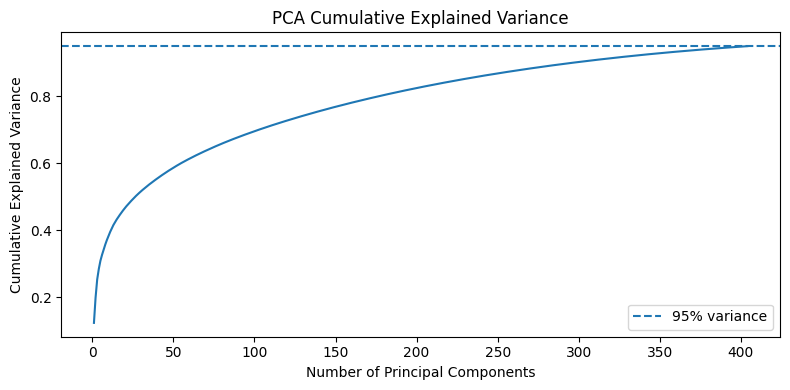

In [12]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(
    figsize=(8, 4)
)

plt.plot(
    np.arange(
        1,
        len(cumulative_variance) + 1
    ),
    cumulative_variance
)

plt.axhline(
    0.95,
    linestyle="--",
    label="95% variance"
)

plt.title(
    "PCA Cumulative Explained Variance"
)

plt.xlabel(
    "Number of Principal Components"
)

plt.ylabel(
    "Cumulative Explained Variance"
)

plt.legend()
plt.tight_layout()
plt.show()

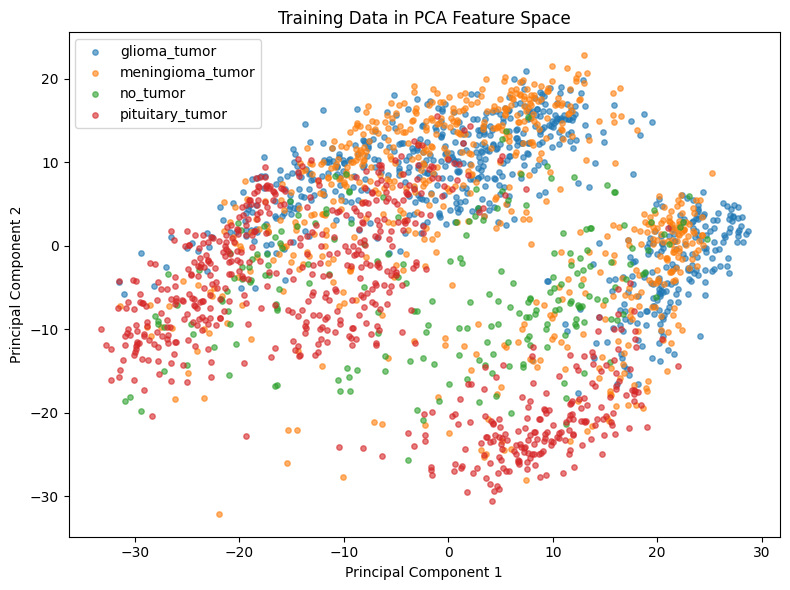

In [13]:
plt.figure(
    figsize=(8, 6)
)

for class_name in sorted(
    np.unique(y_train)
):
    mask = (
        y_train == class_name
    )

    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        s=15,
        alpha=0.6,
        label=class_name
    )

plt.title(
    "Training Data in PCA Feature Space"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.legend()
plt.tight_layout()
plt.show()

## Part 13 — Save final feature datasets

In [14]:
def make_feature_dataframe(
    X,
    labels,
    paths
):
    columns = [
        f"PC{i + 1}"
        for i in range(
            X.shape[1]
        )
    ]

    out = pd.DataFrame(
        X,
        columns=columns
    )

    out.insert(
        0,
        "class_name",
        labels
    )

    out.insert(
        0,
        "processed_path",
        list(paths)
    )

    return out


train_features = make_feature_dataframe(
    X_train_pca,
    y_train,
    train_pre["processed_path"]
)

val_features = make_feature_dataframe(
    X_val_pca,
    y_val,
    val_pre["processed_path"]
)

test_features = make_feature_dataframe(
    X_test_pca,
    y_test,
    test_pre["processed_path"]
)

train_features.to_csv(
    OUTPUT_DIR / "train_pca_features.csv",
    index=False
)

val_features.to_csv(
    OUTPUT_DIR / "validation_pca_features.csv",
    index=False
)

test_features.to_csv(
    OUTPUT_DIR / "test_pca_features.csv",
    index=False
)

pd.DataFrame({
    "component": np.arange(
        1,
        len(
            pca.explained_variance_ratio_
        ) + 1
    ),
    "explained_variance_ratio":
        pca.explained_variance_ratio_,

    "cumulative_explained_variance":
        cumulative_variance
}).to_csv(
    OUTPUT_DIR / "pca_explained_variance.csv",
    index=False
)

summary = {
    "raw_feature_count":
        int(X_train_raw.shape[1]),

    "pca_component_count":
        int(X_train_pca.shape[1]),

    "variance_retained":
        float(
            pca.explained_variance_ratio_.sum()
        ),

    "scaler_fit_on":
        "Training only",

    "pca_fit_on":
        "Training only",

    "validation":
        "Transform only",

    "testing":
        "Transform only"
}

with open(
    OUTPUT_DIR / "member6_summary.json",
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=2
    )

display(
    train_features.head()
)

print(
    "Member 6 outputs saved to:",
    OUTPUT_DIR
)

,processed_path,class_name,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,...,PC395,PC396,PC397,PC398,PC399,PC400,PC401,PC402,PC403,PC404
0,/content/member6_feature_engineering/processed...,glioma_tumor,8.379048,15.710337,2.011803,-13.681764,11.184193,9.383146,-2.291043,2.445121,...,1.628644,-0.327027,1.015266,0.596526,-0.515189,-0.743225,-0.961451,-1.708542,0.945941,-0.116750
1,/content/member6_feature_engineering/processed...,meningioma_tumor,16.392342,18.842125,-1.916027,-10.999578,2.651574,5.557885,4.071336,-6.689990,...,-1.055427,0.452397,0.221207,-0.903665,0.220059,-0.202815,0.424848,-1.740648,1.055850,-0.390177
2,/content/member6_feature_engineering/processed...,no_tumor,11.298750,-21.356312,8.217216,7.279946,2.490049,-3.321537,-5.167914,-0.706282,...,-0.605813,0.766591,-0.025570,-0.681424,-0.568919,-0.876070,-0.605248,-1.128745,-0.848991,0.024423
3,/content/member6_feature_engineering/processed...,pituitary_tumor,-3.884373,6.154109,8.997391,5.237025,-1.720948,-1.294670,4.660583,-6.177575,...,0.048466,0.144232,1.139025,-1.124888,-0.773208,-0.586114,-0.824443,-0.032732,-0.062963,-0.277906
4,/content/member6_feature_engineering/processed...,glioma_tumor,15.696043,-5.400797,-3.028061,3.701405,-9.227275,0.805879,1.617802,5.590392,...,1.286594,-0.717709,0.231339,-0.229741,-0.935490,-0.088813,-0.163730,-0.450193,0.141533,-0.318602


Member 6 outputs saved to: /content/member6_feature_engineering/outputs


## Part 14 — Download Member 6 outputs

In [15]:
ZIP_BASE = WORK / "Member6_HOG_GLCM_PCA_Outputs"

if ZIP_BASE.with_suffix(".zip").exists():
    ZIP_BASE.with_suffix(".zip").unlink()

shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=OUTPUT_DIR
)

ZIP_FILE = ZIP_BASE.with_suffix(
    ".zip"
)

print(
    "Created:",
    ZIP_FILE
)

try:
    from google.colab import files

    files.download(
        str(ZIP_FILE)
    )

except Exception:
    print(
        "Download manually from:",
        ZIP_FILE
    )

Created: /content/member6_feature_engineering/Member6_HOG_GLCM_PCA_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>